<a href="https://colab.research.google.com/github/Sanjana20304/Safe-Robot-Planning-Control/blob/main/tut1_reachability_CandA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, solve_continuous_are
import math

# the library requires "optional" dependencies not available in pip for almost all basic functions,
# but plotting for zonotopes with a small amount of generators works fine.
# Plotting Zonotopes is the only intended use in the tutorial!
# https://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.488.5151&rep=rep1&type=pdf
!pip install git+https://github.com/sadraddini/pypolycontain.git
import pypolycontain as pp

# shapely is used for collision checking. It might not necessarily refer to zonotopes
# but we can always transfer
# https://shapely.readthedocs.io/en/stable/manual.html
from shapely.geometry import box, Polygon, MultiPoint

# for the animations
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

  Cloning https://github.com/sadraddini/pypolycontain.git to /tmp/pip-req-build-jlmrtd2u
  Running command git clone --filter=blob:none --quiet https://github.com/sadraddini/pypolycontain.git /tmp/pip-req-build-jlmrtd2u
  Resolved https://github.com/sadraddini/pypolycontain.git to commit a9aa1a6cff766c06fdb94aaca89a26471b7a9cb4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# (C level) Reachability and object detection using zonotopes

In this part of the tutorial, we will apply the findings of the previous tutorial to a collision-avoidance scenario! Given that we can now compute the permissible space of an autonomous system of the form

$ \dot{x}(t) = A x(t) + d(t) $

were $d(t)$ is a bounded disturbance (in the previous tutorial $u(t)$), we can check the check the collision of two systems when propagated through time.
As such, we will subject a nominally stable object and a controllable 'robot' of the form

$ \dot{x}(t) = A x(t) + B u(t) + d(t)$

to a zonotope collision check. We will use LQR to stabilize the system subjected to our preferences!

# The Object
We consider a moving obstacle which might cause issues for the robot's planned trajectory. We consider the obstacle as a first order integrator system with an uncertain initial position, $\mathcal{N}(\mu,\sigma^2)$. What we do know is that the $x$ and $y$ coordinate of the system are normally distributed according to

$x_0 \sim \mathcal{N}(2.5,0.05)$

$y_0 \sim \mathcal{N}(-3.5,0.055)$

We will first prescribe a zonotope with 2 generators that most closely describes this multivariate Gaussian distribution in the 2 dimensional plane at a confidence interval of 90%.

The true initial position distribution takes a specific shape (ellipse!). We then wish to find the generators that generate a rectangle zonotope that most closely captures this distribution at 90% confidence!

Note that we wish to find the $z_p$ value that scales the standard deviation and captures the probability of laying inside a specific range of real numbers, centered at the mean $\mu$ according to

$ Pr[x \in [\mu-z_p \sigma, \mu+z_p \sigma]] = p$

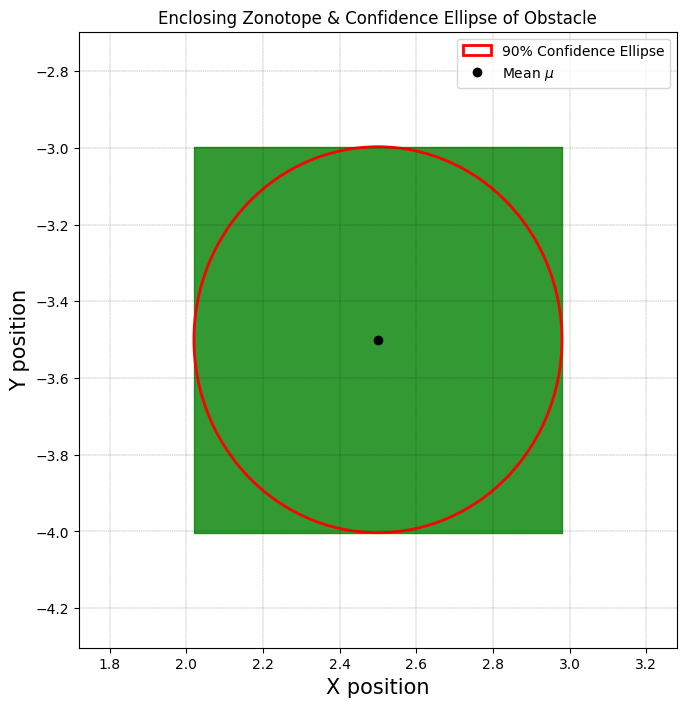

In [6]:
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.stats import chi2

Sigma = np.array([
    [0.05, 0],
    [0, 0.055]
])
Mu = np.array([[2.5], [-3.5]])

confidence = 0.90
s = np.sqrt(chi2.ppf(confidence, df=2))

#Semi-axes lengths along x and y
semi_x = s * np.sqrt(Sigma[0, 0])
semi_y = s * np.sqrt(Sigma[1, 1])

#Generators matrix
g0 = np.array([
    [semi_x, 0.0],
    [0.0, semi_y]
])


z0 = pp.zonotope(x=Mu, G=g0)

#Plotting
fig, ax = plt.subplots(figsize=(7, 7))

pp.visualize([z0], ax=ax, fig=fig)

# Overlay the confidence ellipse (width and height take total axis lengths: 2 * semi_axis)
ellipse = patches.Ellipse(
    xy=(Mu[0, 0], Mu[1, 0]),
    width=2 * semi_x,
    height=2 * semi_y,
    angle=0.0,
    edgecolor='red',
    facecolor='none',
    linewidth=2,
    linestyle='-',
    label=f'{int(confidence*100)}% Confidence Ellipse'
)
ax.add_patch(ellipse)

# Center marker
ax.plot(Mu[0, 0], Mu[1, 0], 'ko', label=r'Mean $\mu$')

# Adjust view limits to clearly see the set
margin = 0.3
ax.set_xlim(Mu[0, 0] - semi_x - margin, Mu[0, 0] + semi_x + margin)
ax.set_ylim(Mu[1, 0] - semi_y - margin, Mu[1, 0] + semi_y + margin)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title('Enclosing Zonotope & Confidence Ellipse of Obstacle')
ax.set_xlabel('X position')
ax.set_ylabel('Y position')
ax.legend(loc='best')

plt.show()

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** The obstacle's initial position is Gaussian, while a zonotope is bounded. What does this mean for a collision-avoidance guarantee based on the chosen confidence region? If the two coordinates are independent and each interval contains 90% of its coordinate's probability, what probability does their rectangular product contain?

</div>

Now, let's take a step back and first generalize the results from the previous part into a function. Given some input data (see below), we want a function that returns the list of zonotopes.

This mostly involves using the code from the previous part and turning it into a function.

In [7]:
def get_zonotopes(A,mu,c0,g0,t,r,color='g',simplify=False):

  # where
  # A: system matrix
  # mu: bounded disturbance
  # c0: initial condition
  # g0: initial generators
  # t: total simulation time
  # r: duration of time-step
  # color: the color of the zonotopes, helps distinguishing later on
  # simplify: do we lower the order of the zonotopes? (already with 2 generators so not always necessary)

  return zts # return the zonotopes
def get_zonotopes(A, mu, c0, g0, t, r, color='g', simplify=False):
    # Number of discrete propagation steps
    n_steps = int(t / r)
    A_norm = np.linalg.norm(A, np.inf)
    e_ra = expm(r * A)

    # Girard constants for continuous curvature and disturbance
    sup_ig = max(np.linalg.norm(g, np.inf) for g in g0.T)
    alpha = (np.exp(r * A_norm) - 1.0 - r * A_norm) * sup_ig
    beta = ((np.exp(r * A_norm) - 1.0) / A_norm) * mu

    beta_box_g = np.diag([beta, beta])
    alpha_beta_box_g = np.diag([alpha + beta, alpha + beta])

    # Step 0: P0 and Q0
    p0_c = (c0 + e_ra @ c0) / 2.0
    g_plus = (g0 + e_ra @ g0) / 2.0
    c_diff = ((c0 - e_ra @ c0) / 2.0).reshape(2, 1)
    g_minus = (g0 - e_ra @ g0) / 2.0
    p0_g = np.hstack((g_plus, c_diff, g_minus))

    q0_c = p0_c
    q0_g = np.hstack((p0_g, alpha_beta_box_g))

    q_c = [q0_c]
    q_g = [q0_g]

    # Propagation loop for i = 1 to n_steps - 1
    for i in range(1, n_steps):
        pi_c = e_ra @ q_c[i - 1]
        pi_g = e_ra @ q_g[i - 1]

        qi_c = pi_c
        qi_g = np.hstack((pi_g, beta_box_g))

        # Optional order reduction via interval hull
        if simplify:
            qi_g = np.diag(np.sum(np.abs(qi_g), axis=1))

        q_c.append(qi_c)
        q_g.append(qi_g)

    # Package into pypolycontain zonotopes for visualization
    zts = []
    for c, g in zip(q_c, q_g):
        # Prevent pypolycontain visualization crash when generators grow large
        if g.shape[1] > 10 and not simplify:
            g_plot = np.diag(np.sum(np.abs(g), axis=1))
        else:
            g_plot = g
        z = pp.zonotope(x=c, G=g_plot)
        z.color = color
        zts.append(z)

    return zts

Now let's call the function for the object and visualize our nominally stable trajectory!

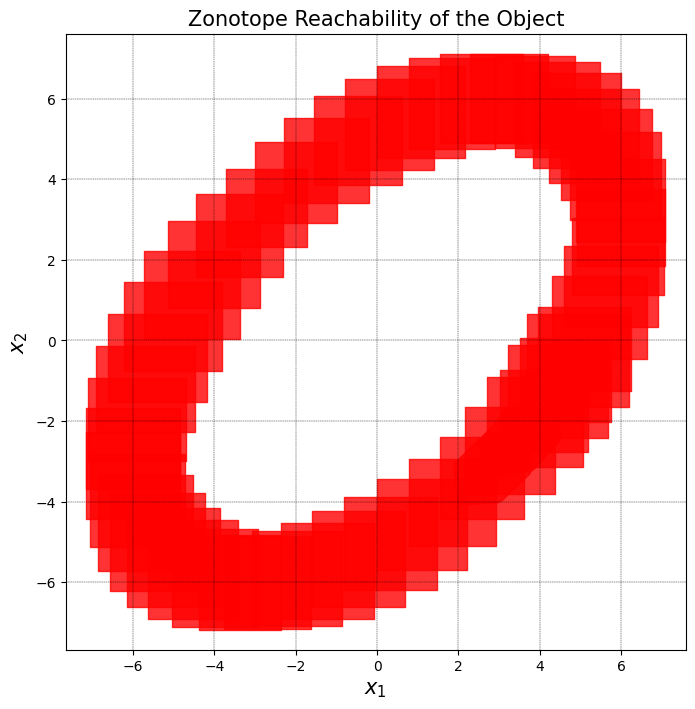

In [9]:
# duration of simulation
sim_duration = 4
r = 0.075
Ac = np.array([[1,-2],[2, -1]])
mu = 0.02 # note that this is the disturbance, not the mean

c0 = Mu
g0 = np.array([[semi_x, 0.0],[0.0, semi_y]])

zts_obj = get_zonotopes(Ac, mu, c0, g0, sim_duration, r, color='r',simplify=False)
fig, ax = plt.subplots()
pp.visualize(zts_obj, title='Zonotope Reachability of the Object', fig=fig, ax=ax)
plt.show()

# The Robot!
Our robot model is given by a similar 2D single-integrator system. As mentioned, this is of the form

$ \dot{x}(t) = A x(t) + B u(t) + d(t)$

$ \begin{bmatrix} \dot{x} \\ \dot{y} \end{bmatrix} = \begin{bmatrix} -1 & 1 \\ -1 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} + \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} u_x \\ u_y \end{bmatrix} + d(t)$

which can be written in the desired autonomous form when a state-feedback control policy is applied. Our state-feedback will be obtained via [LQR](https://en.wikipedia.org/wiki/Linear%E2%80%93quadratic_regulator) which gives us an appropriate state-feedback controller given certain weights on the state deviation and the control input.

For our purposes, we wish to penalize both state-deviation and control input equally in the vertical and horizontal plane. In all situations, we do not penalize any cross-terms. For the state-deviation, we consider a weight of $50$ and for the control input a weight of $5$ respectively.

Below, implement the system and weight matrices and obtain the LQR closed-loop stabilized system by solving the continuous-time algebraic Ricatti equation using the `scipy` package. We then plot the zonotopes of the object and the robot in a single plot (use the color argument in your `get_zonotopes()` function!)

## Some intuition
While "solving the ARE" seems very arbitrary, the intuition is quite straightforward. Note that we have the optimization problem

$ \min(\int_0^{\infty} (x(t)^T Q x(t) + u(t)^T R u(t))dt )$

s.t. $\dot{x}(t) = Ax(t) + Bu(t)$

It turns out that it is easy to solve this problem as we have a quadratic cost and a linear system! The relevant steps are that we first pick a positive definite symmetric matrix $P = P^T$ and add two terms to the cost that cancel eachother out

$ x_0^T P x_0 - x_0^T P x_0 + \int_0^{\infty} (x(t)^T Q x(t) + u(t)^T R u(t))dt$

for which we can take $-x_0^T P x_0$ into the integral sign. Notice that $\frac{d}{dt}(x^T P x) = \dot{x}^T P x + x^T P \dot{x}$ and $\dot{x}$ is something we already know! We get terms that depend on $u$, terms that depend on $x$, and terms that depend on both. The optimization of this unconstrained problem is significantly easier under the assumption that the control input is applied according to $u = -R^{-1}B^TPx$. If you work out the math yourself, it will lead to a cost term where the only thing we can influence is the term $\int_0^{\infty} x^T (A^TP + PA + Q - PBR^{-1}B^TP)x$ for which the term between the state $x^T$ and $x$ is the ARE.

LQR is a valuable control tool as
- It considers an optimal trade-off between user specified system requirements
- It has inherent robustness!
- It has a strong theoretical foundation with an analytical solution!

which makes it a powerful and elegant tool. We will see however, that it is not so simple to address elements commonly found in safe planning and control with pure LQR...

In the next cell, we give you a Q and R but play around with these to get a feeling of how they influence the closed-loop system!



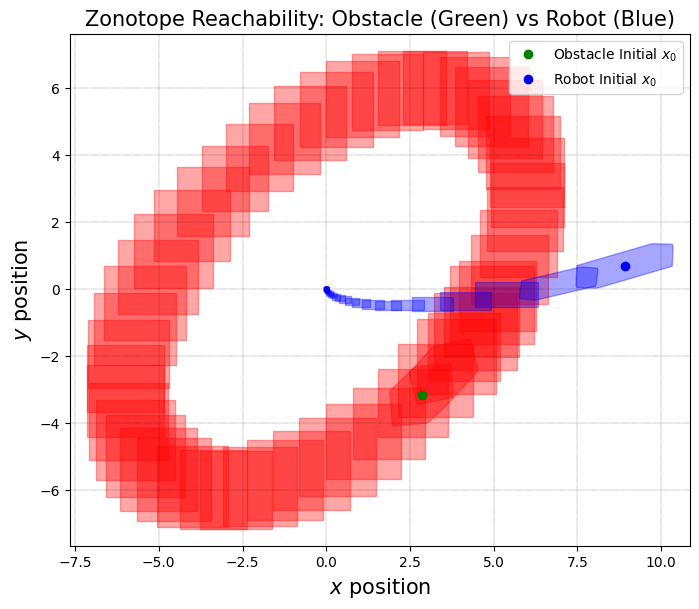

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pypolycontain as pp
from scipy.linalg import solve_continuous_are

# System Dynamics Matrices
A = np.array([
    [-1.0,  1.0],
    [-1.0,  1.0]
])
B = np.array([
    [1.0, 0.0],
    [0.0, 1.0]
])

# Cost Weights (50 for state deviation, 5 for control effort)
Q = np.diag([50.0, 50.0])
R = np.diag([5.0, 5.0])

# Solve Continuous-Time Algebraic Riccati Equation for P
P = solve_continuous_are(A, B, Q, R)

# Compute State-Feedback Gain Matrix K = R^(-1) * B^T * P
K = np.linalg.inv(R) @ B.T @ P

# Closed-Loop System Matrix: x_dot = (A - B*K) x + d
Ac = A - B @ K

# Robot Simulation & Reachability Setup
mu = 0.1
c0 = np.array([[10.0], [1.0]])
g0 = np.array([
    [0.3, 0.0],
    [0.0, 0.3]
])

# Generate reachable zonotopes for the robot
zts_rob = get_zonotopes(
    A=Ac,
    mu=mu,
    c0=c0,
    g0=g0,
    t=sim_duration,
    r=r,
    color='b'
)

# Visualization of both Object and Robot
fig, ax = plt.subplots(figsize=(9, 8))

# Subsample if desired to prevent excessive visual clutter
pp.visualize(
    np.append(zts_obj[::], zts_rob[::]),
    fig=fig,
    ax=ax,
    alpha=0.35,
    title='Zonotope Reachability: Obstacle (Green) vs Robot (Blue)'
)

# Plot initial centers
ax.plot(zts_obj[0].x[0, 0], zts_obj[0].x[1, 0], 'go', label=r'Obstacle Initial $x_0$')
ax.plot(zts_rob[0].x[0, 0], zts_rob[0].x[1, 0], 'bo', label=r'Robot Initial $x_0$')

ax.set_aspect('equal')
ax.grid(True, linestyle=':')
ax.set_xlabel(r'$x$ position')
ax.set_ylabel(r'$y$ position')
ax.legend(loc='best')

plt.show()

Here's an animation function which should give you some indication of what is actually going on:

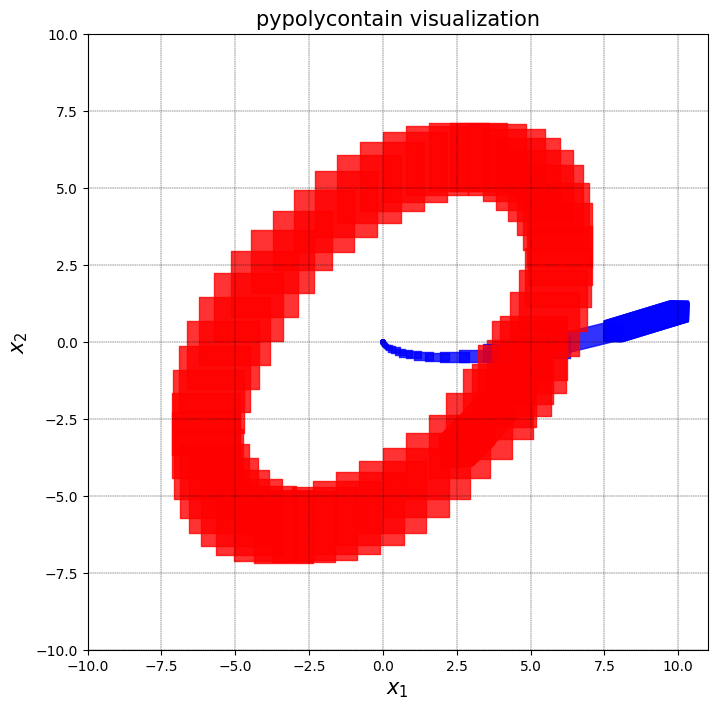

In [11]:
## ANIMATION FUNCTION
def animation_func(i,data):
  zts_obj = data[0]
  zts_rob = data[1]
  pp.visualize([zts_obj[i]], fig=fig, ax=ax)
  pp.visualize([zts_rob[i]], fig=fig, ax=ax)
  ax.set_xlim([-10, 11])
  ax.set_ylim([-10, 10])

fig = plt.figure()
ax = fig.add_subplot(111)
animation = FuncAnimation(fig,animation_func, fargs=((zts_obj,zts_rob),),
                          frames=len(zts_obj), interval=50, blit=False)
HTML(animation.to_html5_video())

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** With LQR feedback $u=-Kx$, the robot has closed-loop dynamics $\dot{x}=(A-BK)x+d$. Why can we apply the same zonotope propagation method to the robot and the obstacle? Does stabilizing the robot at the goal also ensure that its path avoids the obstacle?

</div>

# Collisions!

Given the fact that we limit ourselves to zonotopes with two generators, we can do a simple collision check on two rectangles. This involves checking overlap with 4 conditions given the center and height and width (or edge points) of the rectangles.

Implement this very simple rectangle collision checker in a function:

In [12]:
import numpy as np

def simple_collision_check(zts_obj, zts_rob):
    collision = False

    # Check synchronized steps
    num_steps = min(len(zts_obj), len(zts_rob))

    for k in range(num_steps):
        z_obj = zts_obj[k]
        z_rob = zts_rob[k]

        # Centers
        c_obj = z_obj.x.flatten()
        c_rob = z_rob.x.flatten()

        # Half-widths / radii along x and y
        h_obj = np.sum(np.abs(z_obj.G), axis=1)
        h_rob = np.sum(np.abs(z_rob.G), axis=1)

        # Center-distance conditions along both axes
        collision_x = np.abs(c_obj[0] - c_rob[0]) <= (h_obj[0] + h_rob[0])
        collision_y = np.abs(c_obj[1] - c_rob[1]) <= (h_obj[1] + h_rob[1])

        # Simultaneous overlap along both dimensions indicates collision
        if collision_x and collision_y:
            collision = True
            print(f"Collision detected at step {k}!")
            break

    if not collision:
        print("No collision detected throughout the simulation.")

    return collision

# Run check
simple_collision_check(zts_obj, zts_rob)



Collision detected at step 3!


True

However, this does not generalize to zonotopes with many more generators. A given is that regardless of how many generators a zonotope has, the shape is always convex! As such, we can check the collision via intersection of two convex polytopes which we will construct using shapely.geometry.Polygon.

We could of course check intersection by methods that explicitly rely on zonotopes (e.g. [this](https://graphics.stanford.edu/~anguyen/papers/zonotope.pdf)). You're free to implement these methods, yet using the shapely library suffices for now. We are going to use it later on as well.

Implement this more general collision checker in a function:

In [13]:
import numpy as np
import pypolycontain as pp
from shapely.geometry import Polygon


def polygon_collision_check(zts_obj, zts_rob):
  collision = False
  num_steps = min(len(zts_obj), len(zts_rob))

  for k in range(num_steps):
    z_obj = zts_obj[k]
    z_rob = zts_rob[k]

    # 1: Get the vertices from the zonotopes using zonotope_to_V
    vertices_obj = pp.conversions.zonotope_to_V(z_obj)
    vertices_rob = pp.conversions.zonotope_to_V(z_rob)

    # 2: Convert the vertices into shapely Polygons
    poly_obj = Polygon(vertices_obj)
    poly_rob = Polygon(vertices_rob)

    # 3: Check geometric intersection
    if poly_obj.intersects(poly_rob):
      collision = True
      print(f"Collision detected at step {k} (time t ≈ {k * r:.3f} s)!")
      break

  if not collision:
    print(
        "No collision detected throughout the simulation via Polygon"
        " intersection."
    )

  return collision


# Run collision check
polygon_collision_check(zts_obj, zts_rob)

Collision detected at step 3 (time t ≈ 0.225 s)!


True

Are we in collision according to your checks?
Note that the LQR controller does not take into account the obstacle at all! This is a major drawback of LQR for safe planning and control.

For the following, if you're in collision, you're good to go. Otherwise, change $Q$ and $R$ until you are in collision.

Note the old and new cost terms down somewhere!

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** Use your collision checks to answer the following questions and explain your reasoning.

1. If the robot and obstacle zonotopes overlap for the same time interval, does this prove that a collision occurs? What can we conclude if their conservative enclosures are disjoint for every interval?
2. Could the union of the robot's reachable sets overlap the union of the obstacle's reachable sets even when every matching pair is disjoint? Explain why the time indices matter.
3. Does a zonotope with two generators necessarily form an axis-aligned rectangle? When is the simple coordinate-overlap check sufficient, and when would you use the polygon check?

</div>

# (A level) Collision! What to do now?
What you have been doing so far is often referred to as $\textit{verification}$ process since you are using the knowledge of your system to analyze whether some desired specification (do not collide with an obstacle) holds or not.

In the next couple of steps, you're gonna look into the so called $\textit{synthesis}$ process in which you are given a desired system specification and you design a control strategy $u$ such that the specification holds. Specifically, you're gonna design different Control Barrier Functions (CBFs) to guarantee that the robot stays within an obstacle-free safeset. CBFs have been covered in the lectures but if you would like to refresh your knowledge you might want to have a look at $\href{https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=8796030&casa_token=CtgTXVjMhTAAAAAA:93TomzH638Rg17rJl9LRW5WYljATBuiBor0OkfvSXwvZ-Y0rO-xkOhK15JBWIqrcIDgnqlEX}{this} $ publication.

# Simple yet provably safe controller
First, we will design a very conservative barrier function. In this case, we would like to obtain a halfspace constraint that contains all possible obstacle locations. If we can design a controller that stays within this obstacle-free halfspace, we are guaranteed to avoid collisions.


Such a halfspace can be defined as $\mathcal{H} = \left\{ x \in \mathbb{R}^n \mid a^T x \leq b\right\}$. Recall, that any polygon can also be written as an intersection of halfspaces. Convince yourself that the convex hull of all obstacle location from $t=0, \dots , T$ contains all possible locations the obstacle might be at. In the following, try to find this convex polygon and visualize it!

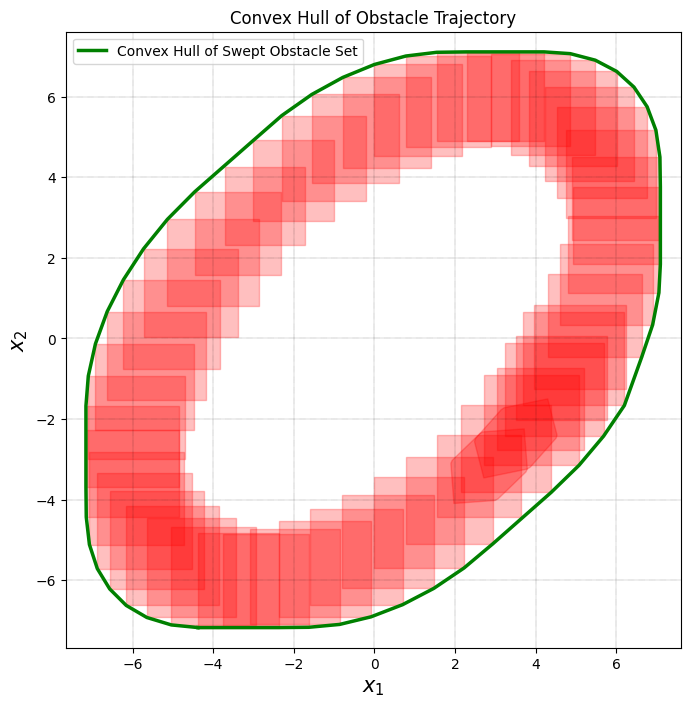

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pypolycontain as pp
from shapely.geometry import MultiPoint

# Trajectory of the obstacle in V-form (collect all vertices)
# Note: pp.zonotope_to_V returns array of shape (2, num_vertices) or (num_vertices, 2)
# The comprehension extracts all individual [x, y] vertex pairs
all_vertices = []
for z in zts_obj:
  v = pp.zonotope_to_V(z)
  # Ensure shape is (num_vertices, 2)
  if v.shape[0] == 2:
    v = v.T
  all_vertices.extend(v.tolist())

# Or keeping your one-liner format:
obj_trajectory = [
    pp.zonotope_to_V(zts_obj[i]).tolist()[j]
    for i in range(len(zts_obj))
    for j in range(len(pp.zonotope_to_V(zts_obj[i]).tolist()))
]

# Convex hull of the entire obstacle trajectory
conv_hull_obj = MultiPoint(obj_trajectory).convex_hull

# Extract boundary coordinates for plotting
x, y = conv_hull_obj.exterior.coords.xy

# Visualization
fig, ax = plt.subplots(figsize=(8, 8))

# Draw the underlying zonotopes
pp.visualize(zts_obj, fig=fig, ax=ax, alpha=0.25)

# Plot the enclosing convex hull boundary in green
ax.plot(x, y, 'g-', linewidth=2.5, label='Convex Hull of Swept Obstacle Set')

ax.set_aspect('equal')
ax.grid(True, linestyle=':')
ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_title('Convex Hull of Obstacle Trajectory')
ax.legend(loc='best')

plt.show()

Next, in order to define our barrier function, we need the convex hull of the obstacle trajectory in halfspace form (H-polytope). Unfortunatel, the function provided in `pypolycontain` does not work properly, so we have to do the conversion ourselves. Recall that each edge of the polytope between two consecutive vertices $V_i$ and $V_{i+1}$ can be described as a linear function of the form $a^T x - b = 0$.

Note, that the convex hull has many vertices, so we would like to create a list of tuples that contains all the halfspaces $halfspaces = [(a_0, b_0), \dots, (a_{N-1}, b_{N-1})]$ where $N$ is the number of vertices. Since it can be tideous to find the correct sign of the halfspaces, this function is provided in the following. Try to understand the code!

/tmp/ipykernel_841/1387564208.py:16: RuntimeWarning: invalid value encountered in scalar divide
  a = [-dy / abs(dx), 1]


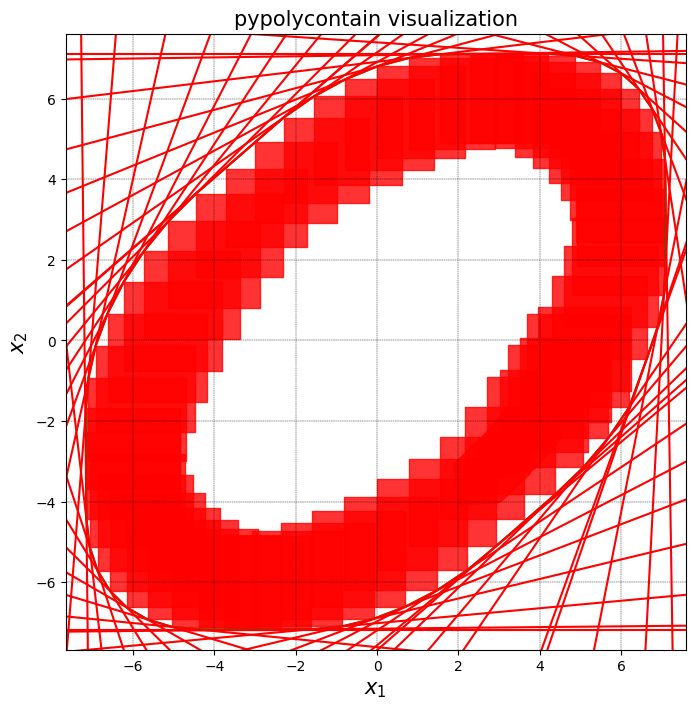

In [15]:
vertices = np.array([[x[i], y[i]] for i in range(len(x))])

def construct_halfspaces(vertices_list):
  halfspaces = []

  for i in range(len(vertices_list)-1):
    # vertex i
    p1 = vertices[i]
    # vertex i+1
    p2 = vertices[i+1]

    # change in x and y
    dx = p2[0] - p1[0]
    dy = (p2[1] - p1[1]) * np.sign(dx)

    a = [-dy / abs(dx), 1]
    b = a[0] * p1[0] + a[1] * p1[1]
    if dx < 0:
      a = [-a[0], -a[1]]
      b *= -1
    halfspaces.append((a, b))

  return halfspaces

halfspaces = construct_halfspaces(vertices.tolist())

# visualize all the halfspaces
pp.visualize(zts_obj)
plt.plot(x,y,'g')
for ab in halfspaces:
  plt.plot([-10,10], [(ab[1] - ab[0][0] * (-10)) / ab[0][1], (ab[1] - ab[0][0] * (10)) / ab[0][1]], 'r')
plt.show()


Now, any of these halfspaces could be used as a candidate CBF since the intersection of all halfspaces $\mathcal{O} = \left\{x \in \mathbb{R}^n \mid \bigwedge_{i=0}^{N-1} a_i^T x \leq b_i \right\}$ represents the obstacle region and, thus, if any of the halfspace constraints is violated, i.e. $\bigvee_{i=0}^{N-1} a_i^T x \geq b_i$, then the robot is outside of the obstacle region $\mathcal{O}$.

The question that remains is: Which one is the most suitable halfspace constraint? It's a design choice! We would like to obtain a halfspace that contains the initial position of the robot $x_0$ and allows us to get as close as possible to the goal $g = [0, 0]$. Hint: use the distance between a point and a line!

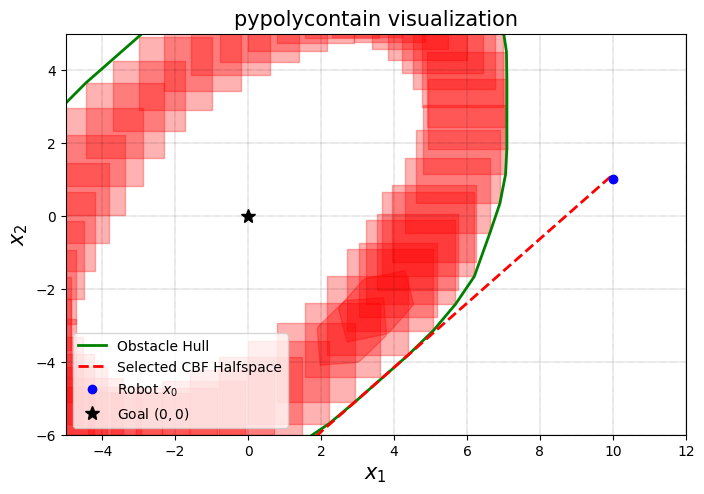

In [16]:
# Initial robot position and target goal
x0 = np.array([10.0, 1.0])
goal = np.array([0.0, 0.0])

coords = list(conv_hull_obj.exterior.coords)
min_dist = np.inf
a_min = None
b_min = None

for i in range(len(coords) - 1):
  p1 = np.array(coords[i])
  p2 = np.array(coords[i + 1])

  # Edge tangent vector and outward normal candidate
  edge = p2 - p1
  normal = np.array([edge[1], -edge[0]])
  norm_val = np.linalg.norm(normal)

  if norm_val < 1e-9:
    continue

  normal = normal / norm_val
  b = np.dot(normal, p1)

  # Orient normal outward so the obstacle hull lies in a^T x <= b
  # (Check against the centroid of the convex hull)
  centroid = np.array(conv_hull_obj.centroid.coords[0])
  if np.dot(normal, centroid) > b:
    normal = -normal
    b = -b

  # The safe region is the complement: a^T x >= b.
  # Constraint 1: The safe halfspace must contain the robot's initial position x0
  if np.dot(normal, x0) >= b:
    # Signed distance from the goal g=[0, 0] to the separating boundary a^T x = b
    # d = (a^T g - b) / ||a||. Since ||a|| = 1:
    dist_to_goal = np.abs(np.dot(normal, goal) - b)

    # Select the hyper-plane that allows getting closest to the goal
    if dist_to_goal < min_dist:
      min_dist = dist_to_goal
      a_min = normal
      b_min = b

# Visualization
fig, ax = plt.subplots(figsize=(8, 8))
pp.visualize(zts_obj, fig=fig, ax=ax, alpha=0.3)
ax.plot(x, y, 'g', linewidth=2, label='Obstacle Hull')

# Plot the chosen separating hyperplane line: a_min[0]*x + a_min[1]*y = b_min
x_vals = np.array([-10.0, 10.0])
y_vals = [(b_min - a_min[0] * xv) / a_min[1] for xv in x_vals]
ax.plot(x_vals, y_vals, 'r--', linewidth=2, label='Selected CBF Halfspace')

ax.plot(x0[0], x0[1], 'bo', label='Robot $x_0$')
ax.plot(goal[0], goal[1], 'k*', markersize=10, label='Goal $(0,0)$')

ax.set_xlim(-5, 12)
ax.set_ylim(-6, 5)
ax.set_aspect('equal')
ax.grid(True, linestyle=':')
ax.legend(loc='best')
plt.show()

Let's define our CBF! Remember, the safeset which we would like to render invariant (basically means if we are inside the set, we will remain in the set) is of the form

$\mathcal{C} = \left\{x \in \mathbb{R}^n \mid h\left(x, t\right) \geq 0 \right\}$

where our barrier function $h$ might depend explicitly on time. In our first scenario, however, we generate a constant CBF so there won't be any time dependencies.

In [17]:
h_static = lambda x, t: np.dot(a_min, x.flatten()) - b_min

## Control Synthesis!
Now that we've defined our CBF, we need to synthesize control inputs $u$ which render $\mathcal{C}$ invariant. Have a look at the lectures (or the linked paper) again and convince yourself that

$\dot{h}\left(x, t\right) \geq - \gamma h\left(x, t\right)$

ensures invariance. By applying the chain rule to the above constraint, we can obtain an expression

$\dot{h}(x, t) = \frac{\partial h }{\partial x} \dot{x} + \frac{\partial h}{\partial t} = \frac{\partial h }{\partial x} (Ax + Bu + d) + \frac{\partial h}{\partial t} \geq -\gamma h(x, t)$

which is linear in the control input and, thus, this constraint can be included in convex optimization problems!

Basically, what we want to do now is to develop a safety filter that takes as input a reference control input $u_{ref}$, e.g. the LQR control input, and outputs a safe control input that satisfies the safety constraint. Additionally, this modified control input should be as close as possible to the reference input so that the robot follows its reference controller and the safety filter only intervenes if we're about to violate the safety specification. This can be formulated as an optimization problem

$$
\begin{aligned}
	\min_{u} \quad &(u - u_{ref})^T Q (u - u_{ref})\\
	\textrm{s.t.  } \quad  &\frac{\partial h }{\partial x} (Ax + Bu + d) + \frac{\partial h}{\partial t} \geq - \gamma h(x, t)
    \end{aligned}.
$$

which is a quadratic program (QP) and, thus, can be solved efficiently. For the following simulations simply assume that the robot disturbance is zero, i.e. $d=0$.

In order to solve the optimization problem, we will make use of python convex optimization package `cvxopt`. Please have a look at $\href{https://cvxopt.org/examples/tutorial/qp.html}{this} $ example of how to formulate and solve a QP in python. Hint: formulate the optimization using the decision variable $\tilde{u} = u - u_{ref}$ which requires slight modification of the safety constraint.

In [18]:
# Some imports for the CBF formulation
from scipy.integrate import odeint
from math import sin, cos, sqrt, atan2, pi
from cvxopt import matrix, solvers

Let's define the function of the safety filter!

In [25]:
def safety_filter(x, h_func, t):
  gamma = 10.0

  x_vec = np.array(x).reshape(2, 1)

  # 1. Reference control input: LQR state feedback
  u_ref = -K @ x_vec  # shape (2, 1)

  # 2. Barrier function evaluation and gradients
  # .item() safely extracts the value as a Python float regardless of array dimensions
  a_vec = np.array(a_min).reshape(1, 2)
  b_val = float(np.array(b_min).squeeze())

  h_val = (a_vec @ x_vec - b_val).item()

  dhdx = a_vec
  dhdt = 0.0

  # 3. Set up QP in terms of u_tilde = u - u_ref
  Q_qp = 2.0 * np.eye(2)
  p_qp = np.zeros((2, 1))

  # Constraint: - (dh/dx * B) * u_tilde <= dh/dx * (A*x + B*u_ref) + dh/dt + gamma * h(x)
  G_qp = -dhdx @ B  # shape (1, 2)
  h_qp = (dhdx @ (A @ x_vec + B @ u_ref) + dhdt + gamma * h_val).item()

  # Convert to cvxopt double matrices
  Q_cvx = matrix(Q_qp, tc='d')
  p_cvx = matrix(p_qp, tc='d')
  G_cvx = matrix(G_qp, tc='d')
  h_cvx = matrix([[h_qp]], tc='d')  # shape (1, 1)

  # 4. Solve the QP
  solvers.options['show_progress'] = False
  sol = solvers.qp(Q_cvx, p_cvx, G_cvx, h_cvx)

  u_tilde = np.array(sol['x']).reshape(2, 1)

  # 5. Output safe control input
  u_safe = (u_tilde + u_ref).flatten()

  return u_safe

Now we're gonna run a simple simulation which should show that the static halfspace constraint is always satisfied. To do so, we need to define the closed loop system and call a differential equation solver!

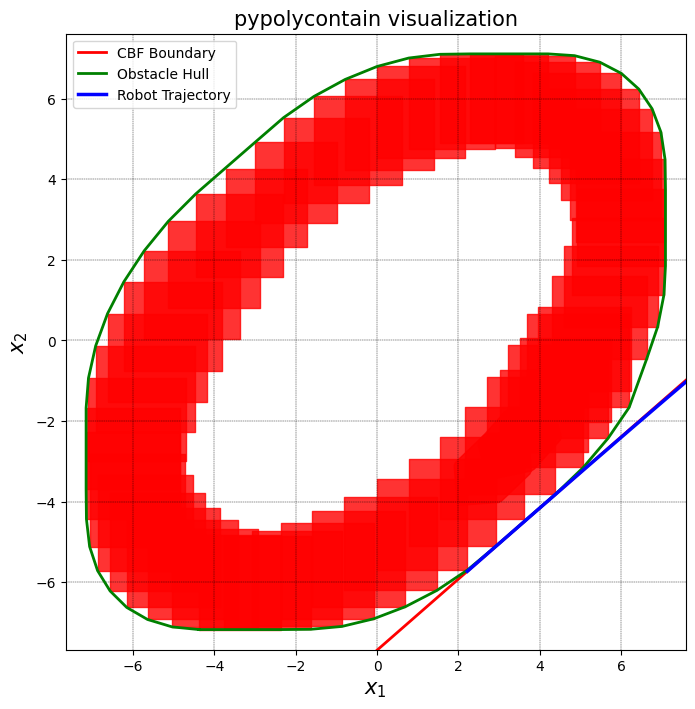

In [26]:
def closed_loop_system(x, t):
  # 1. Compute safe control input via CBF safety filter
  u = safety_filter(x, None, t)

  # 2. Continuous system dynamics: dx/dt = A*x + B*u (assuming d = 0)
  dx = A @ x.reshape(2, 1) + B @ u.reshape(2, 1)

  return dx.flatten()


# Initial Conditions (ensure c0 is a 1D vector of shape (2,) for odeint)
c0_flat = np.array(c0).flatten()
t_sim = np.linspace(0, sim_duration, 300)

x_sol = odeint(closed_loop_system, c0_flat, t_sim)

fig, ax = plt.subplots(figsize=(8, 8))
pp.visualize(zts_obj, fig=fig, ax=ax)
plt.plot(
    [-10, 10],
    [
        (b_min - a_min[0] * (-10)) / a_min[1],
        (b_min - a_min[0] * (10)) / a_min[1],
    ],
    'r',
    linewidth=2,
    label='CBF Boundary',
)
plt.plot(x, y, 'g', linewidth=2, label='Obstacle Hull')
plt.plot(x_sol[:, 0], x_sol[:, 1], 'b', linewidth=2.5, label='Robot Trajectory')
plt.legend()
plt.show()

## Let's see an animated version!
It might take a while to visualize.

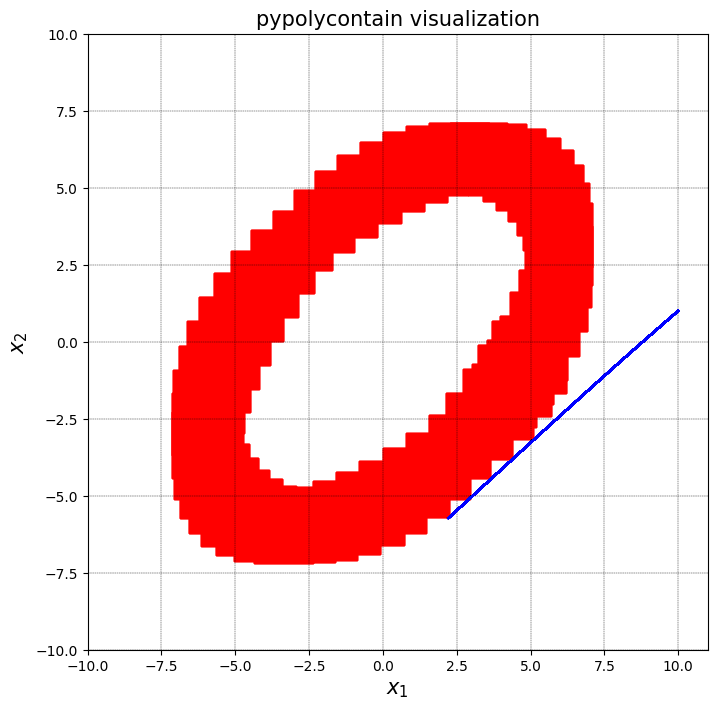

In [27]:
## ANIMATION FUNCTION
def animation_func(i,data):
  current_t = i * (sim_duration / len(t_sim))
  zts_obj = data[0]
  robot_pos = data[1]
  pp.visualize([zts_obj[min(len(zts_obj)-1, int(np.floor(current_t / r)))]], fig=fig, ax=ax)
  plt.plot(robot_pos[0:i, 0], robot_pos[0:i, 1], 'b')
  ax.set_xlim([-10, 11])
  ax.set_ylim([-10, 10])

fig = plt.figure()
ax = fig.add_subplot(111)
animation = FuncAnimation(fig,animation_func, fargs=((zts_obj,x_sol),),
                          frames=len(t_sim)-1, interval=50, blit=False)
HTML(animation.to_html5_video())

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** The static barrier keeps the robot on the exterior side of one face of the convex hull of the obstacle's reachable sets. Why does this ensure separation under the model assumptions? Explain how this construction can prevent the robot from reaching the goal even after the obstacle has moved away.

</div>

## Safe? yes! Is it what we want? No..
From this simulation we can observe that the robot indeed stays safe at all time, i.e. it does not collide with the dynamic obstacle. However, it is also rather conservative since the robot stays in the safe halfspace although the obstacle is far away. How can we change that? The key is to consider a timevarying control barrier function that changes whenever the obstacle is moving. In this section we will look into more sophisticated CBFs that will change over time. In this way, we will not only ensure safety but also ensure that our robot reaches its destination!

One requirement of a valid CBF is that it's continuous in time and continuously differentiable with respect to $x$ and $t$. Since we only have the obstacle zonotopes at discrete time steps, we will use a simple linear time interpolation for the obstacle between time steps $t_k$ and $t_{k+1}$.

The following function takes the current time as well as the list of discrete zonotopes and returns a polytope in vertex form (V_polytope) at the current time.

In [37]:
import numpy as np
import pypolycontain as pp


def cont_time_obstacle(t, zonotopes_obst):
  # Clamp t within simulation bounds [0, t_final]
  t_max = (len(zonotopes_obst) - 1) * r
  t_clamped = np.clip(t, 0.0, t_max)

  # Find surrounding discrete step indices k and k+1
  idx_last = int(np.floor(t_clamped / r))
  idx_next = min(idx_last + 1, len(zonotopes_obst) - 1)

  # Surrounding time stamps
  t_last = idx_last * r
  t_next = idx_next * r

  # Vertices of the obstacle at t_last and t_next in V-representation
  # pp.zonotope_to_V returns array of shape (dim, num_vertices); transpose to (num_vertices, 2)
  v_last = pp.zonotope_to_V(zonotopes_obst[idx_last])
  if v_last.shape[0] == 2:
    v_last = v_last.T

  v_next = pp.zonotope_to_V(zonotopes_obst[idx_next])
  if v_next.shape[0] == 2:
    v_next = v_next.T

  obst_last = v_last
  obst_next = v_next

  # Linear interpolation weight lambda in [0, 1]
  if idx_last == idx_next:
    lam = 0.0
  else:
    lam = (t_clamped - t_last) / (t_next - t_last)

  # Obstacle at current time t as V-representation
  obst_t = (1.0 - lam) * obst_last + lam * obst_next

  return obst_t



Now we have a function to call that provides us with a polytope representation of the obstacle at any time. However, we still need to ensure that our robot is always outside of the polytope. There are different ways to ensure collision avoidance, e.g. taking the distance between a point and a polygon. However, this would be a nonsmooth measure in $x$ which is why we consider an overapproximating circle in the following.

Find the smallest circle that contains the entire polytope at time t!

In [31]:
def bounding_radius(t, zonotopes_obst):
  t_max = (len(zonotopes_obst) - 1) * r
  t_clamped = np.clip(t, 0.0, t_max)

  ind = int(np.floor(t_clamped / r))
  idx0 = min(ind, len(zonotopes_obst) - 1)
  idx1 = min(ind + 1, len(zonotopes_obst) - 1)

  t0 = idx0 * r
  t1 = idx1 * r

  # Centers
  z_c0 = zonotopes_obst[idx0].x.flatten()
  z_c1 = zonotopes_obst[idx1].x.flatten()

  # Interpolated center
  if idx0 == idx1 or np.isclose(t1, t0):
    z_c = z_c0
    lam = 0.0
  else:
    lam = (t_clamped - t0) / (t1 - t0)
    z_c = (1.0 - lam) * z_c0 + lam * z_c1

  # Compute exact radius for idx0 from its vertices
  v0 = pp.zonotope_to_V(zonotopes_obst[idx0])
  if v0.shape[0] == 2:
    v0 = v0.T
  r0 = np.max(np.linalg.norm(v0 - z_c0, axis=1))

  # Compute exact radius for idx1 from its vertices
  v1 = pp.zonotope_to_V(zonotopes_obst[idx1])
  if v1.shape[0] == 2:
    v1 = v1.T
  r1 = np.max(np.linalg.norm(v1 - z_c1, axis=1))

  # Linearly interpolate the bounding radius
  r_bound = float((1.0 - lam) * r0 + lam * r1)

  return z_c, r_bound

Let's check if our bounding circle algorithm works properly!

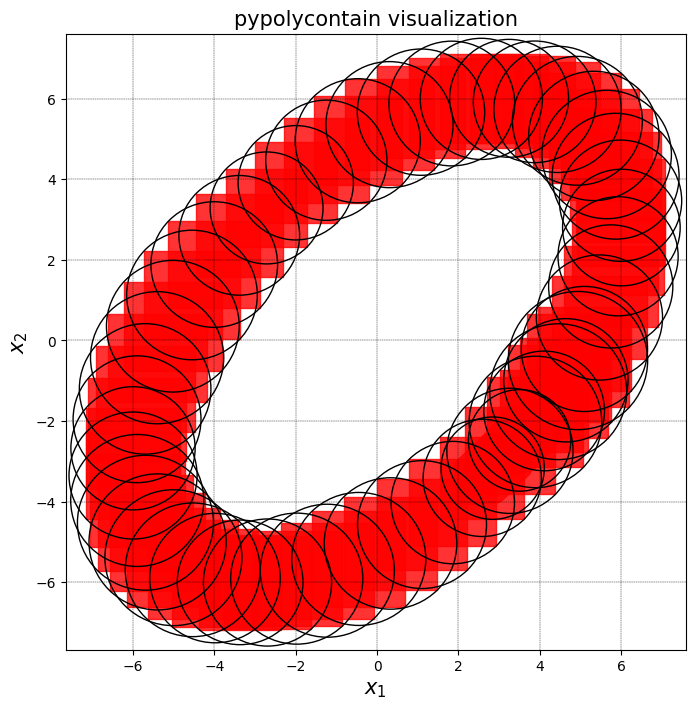

In [32]:
from matplotlib.patches import Circle

fig, ax = plt.subplots()
pp.visualize(zts_obj, fig=fig, ax=ax)
for i in range(len(zts_obj)):
  tnow = i * r
  center, radius = bounding_radius(tnow, zts_obj)
  ax.add_artist(Circle(center, radius, fill=False))
plt.show()

In the case of a CBF that explicitly depends on time, we need to to account for the known change of the obstacle over time. In this case, the explicit CBF time derivative $\frac{\partial h}{\partial t}$ is nonzero.

However, since the explicit time dependency is not exactly known in our case (as a result of discrete reachibility analysis and time interpolation), we approximate the time derivative of the barrier function using finite differences. To be specific, we will use a simple forward difference method

$\frac{\partial f}{\partial t} (t) \approx \frac{f\left(t + \delta t\right) - f\left(t\right)}{\delta t}$.

The CBF we consider is given as

$h(x, t) = \lVert x - c_{obs}(t) \rVert_2 - r_{obs}(t) \geq 0$

In the following, write a function that returns the value of the CBF $h(x, t)$, its gradient $\frac{\partial h}{\partial x}$ as well as its explicit time derivative $\frac{\partial h}{\partial t}$. Hint: you need to apply the chain rule for the gradient and the time derivative. Approximate explicit time derivatives $\frac{\partial c_{obs}}{\partial t}$ and $\frac{\partial r_{obs}}{\partial t}$ using finite differences.

In [33]:
import numpy as np

def cbf_dynamic(x, t):
    # Input: state defined as x = [x_robot, y_robot]
    # Output: Value of CBF h_val, gradient with respect to x dhdx, explicit time derivative dhdt

    # Ensure x is a 1D array of shape (2,)
    x_vec = np.array(x).flatten()

    # 1. Obstacle center and radius at current time t
    c_t, r_t = bounding_radius(t, zts_obj)
    c_t = np.array(c_t).flatten()
    r_t = float(r_t)

    # Position difference vector from obstacle center to robot
    diff = x_vec - c_t

    # 2. CBF value: h(x, t) = ||x - c_obs(t)||^2 - r_obs(t)
    # (Note: if r_obs in your formula represents squared radius, use r_t**2.
    # Here we follow the exact prompt formula: ||x - c||^2 - r_obs)
    h_val = float(np.dot(diff, diff) - r_t)

    # 3. Spatial gradient dh/dx = 2 * (x - c_obs(t))^T (shape: 1x2)
    dhdx = (2.0 * diff).reshape(1, 2)

    # 4. Numerical approximation of explicit time derivatives via forward differences
    dt = 1e-4
    c_next, r_next = bounding_radius(t + dt, zts_obj)
    c_next = np.array(c_next).flatten()
    r_next = float(r_next)

    dc_dt = (c_next - c_t) / dt
    dr_dt = (r_next - r_t) / dt

    # dh/dt = -2 * (x - c_obs)^T * (dc_obs/dt) - dr_obs/dt
    dhdt = float(-2.0 * np.dot(diff, dc_dt) - dr_dt)

    return h_val, dhdx, dhdt

# Test
print(cbf_dynamic(c0, 0))

(67.29558394054531, array([[14.31056632,  8.33480171]]), -202.86460364033059)


Now, we will define the safety filter similarly to the safety filter using the static CBF. Set up the QP and run the continuous time simulation. What can you observe? Try different parameter settings for $\gamma = [1, 10, 30]$. Also, plot the value of $h(x, t)$ over time for different values of $\gamma$. What is the trade-off when choosing large values of $\gamma$?

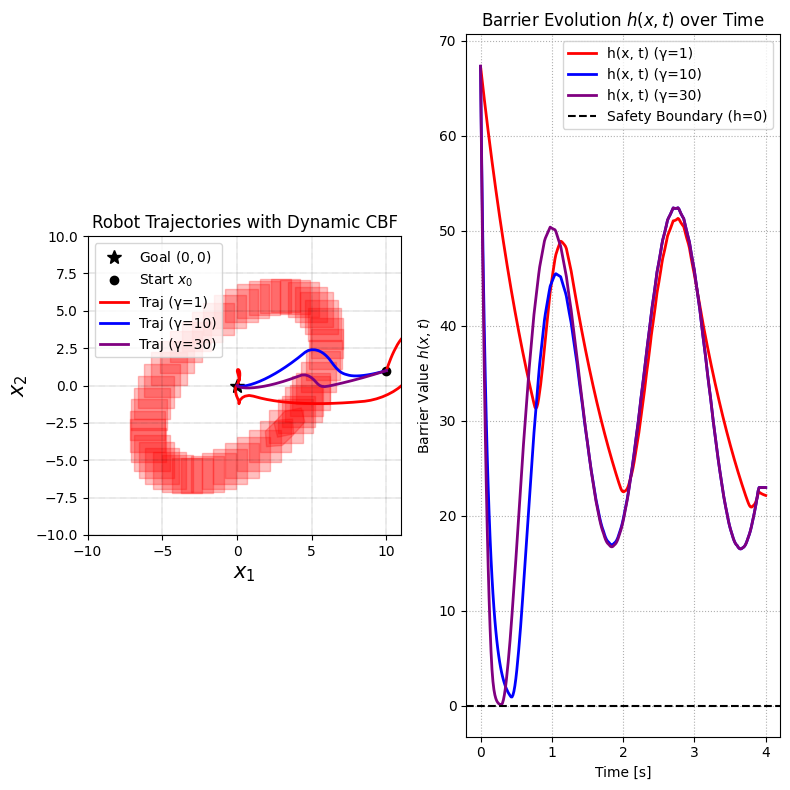

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pypolycontain as pp
from cvxopt import matrix, solvers
from scipy.integrate import odeint

# Global gamma tracker for closed_loop_system calls
current_gamma = 10.0


def safety_filter(x, t, gamma=10.0):
  # Ensure state is a column vector
  x_vec = np.array(x).reshape(2, 1)

  # 1. Nominal LQR control: u_ref = -K * x
  u_ref = -K @ x_vec  # shape (2, 1)

  # 2. Dynamic barrier values from cbf_dynamic
  h_val, dhdx, dhdt = cbf_dynamic(x_vec.flatten(), t)
  dhdx = np.array(dhdx).reshape(1, 2)

  # 3. Formulate QP in terms of u_tilde = u - u_ref
  Q_qp = 2.0 * np.eye(2)
  p_qp = np.zeros((2, 1))

  # Constraint: - (dhdx * B) * u_tilde <= dhdx * (A*x + B*u_ref) + dhdt + gamma * h_val
  G_qp = -dhdx @ B  # shape (1, 2)

  # Use .item() to safely extract the scalar value without dimension errors
  term1 = (dhdx @ (A @ x_vec + B @ u_ref)).item()
  rhs_val = float(term1 + dhdt + gamma * h_val)

  Q_cvx = matrix(Q_qp, tc='d')
  p_cvx = matrix(p_qp, tc='d')
  G_cvx = matrix(G_qp, tc='d')
  h_cvx = matrix([[rhs_val]], tc='d')

  # 4. Solve the QP
  solvers.options['show_progress'] = False
  try:
    sol = solvers.qp(Q_cvx, p_cvx, G_cvx, h_cvx)
    u_tilde = np.array(sol['x']).reshape(2, 1)
  except (ValueError, ArithmeticError):
    u_tilde = np.zeros((2, 1))

  # 5. Filtered safe control: u_safe = u_tilde + u_ref
  u_safe = (u_tilde + u_ref).flatten()
  return u_safe


def closed_loop_system(x, t):
  # Compute safe control input
  u = safety_filter(x, t, gamma=current_gamma)

  # Continuous system dynamics: x_dot = A*x + B*u (d = 0)
  dx = A @ np.array(x).reshape(2, 1) + B @ u.reshape(2, 1)
  return dx.flatten()


# Simulation setup
t_sim = np.linspace(0, sim_duration, 300)
c0_flat = np.array(c0).flatten()

# Compare trajectories and barrier values across gamma in [1, 10, 30]
gammas = [1.0, 10.0, 30.0]
colors = ['red', 'blue', 'purple']

fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

# Visualize obstacle sets on the trajectory subplot
pp.visualize(zts_obj, fig=fig, ax=ax1, alpha=0.25)
ax1.plot(0, 0, 'k*', markersize=10, label='Goal $(0,0)$')
ax1.plot(c0_flat[0], c0_flat[1], 'ko', markersize=6, label='Start $x_0$')

for gamma_val, col in zip(gammas, colors):
  current_gamma = gamma_val

  # Simulate closed loop system
  x_sol = odeint(closed_loop_system, c0_flat, t_sim)

  # Plot trajectory in state space
  ax1.plot(
      x_sol[:, 0],
      x_sol[:, 1],
      color=col,
      linewidth=2,
      label=f'Traj (γ={int(gamma_val)})',
  )

  # Compute and plot h(x, t) profile over time
  h_profile = [cbf_dynamic(x_sol[i], t_sim[i])[0] for i in range(len(t_sim))]
  ax2.plot(
      t_sim,
      h_profile,
      color=col,
      linewidth=2,
      label=f'h(x, t) (γ={int(gamma_val)})',
  )

# Formatting Left Plot (State Space)
ax1.set_xlim([-10, 11])
ax1.set_ylim([-10, 10])
ax1.set_aspect('equal')
ax1.grid(True, linestyle=':')
ax1.set_xlabel(r'$x_1$')
ax1.set_ylabel(r'$x_2$')
ax1.set_title('Robot Trajectories with Dynamic CBF')
ax1.legend(loc='best')

# Formatting Right Plot (Barrier Value vs Time)
ax2.axhline(
    0.0,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Safety Boundary (h=0)',
)
ax2.grid(True, linestyle=':')
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Barrier Value $h(x, t)$')
ax2.set_title(r'Barrier Evolution $h(x, t)$ over Time')
ax2.legend(loc='best')

plt.tight_layout()
plt.show()

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** For the moving-circle barrier $h(x,t)=\|x-c_{obs}(t)\|_2-r_{obs}(t)$, explain the role of the explicit time derivative $\partial h/\partial t$ in the safety constraint. What could go wrong if we omitted it while the obstacle moved toward a stationary robot or its uncertainty radius increased?

</div>

Lastly, we can see our robot in action! In this simulation section, you have been working on safe control synthesis in a reactive setting meaning that obstacle avoidance is guaranteed but it also could have been avoided at all if this problem would have been tackled at a higher level such as motion planning. Nonetheless, CBFs are an amazing tool for safety guarantees on a control level. There are many different topics that you could explore from here, e.g. robust CBFs, CBFs under uncertainties, CBFs for multi-agent systems, CBFs for safe reinforcement learning and many more!

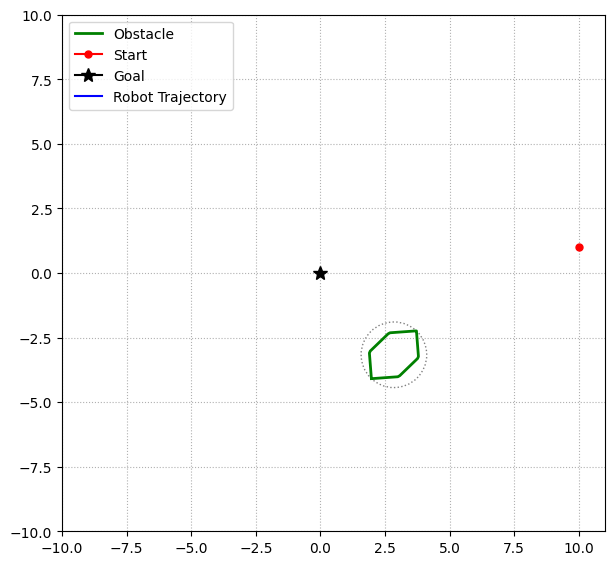

In [40]:
import numpy as np
import pypolycontain as pp
from shapely.geometry import MultiPoint
from matplotlib.patches import Circle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt

# 1. Self-contained robust cont_time_obstacle to prevent shape broadcast errors
def cont_time_obstacle(t, zonotopes_obst):
    t_max = (len(zonotopes_obst) - 1) * r
    t_clamped = np.clip(t, 0.0, t_max)

    idx_last = int(np.floor(t_clamped / r))
    idx_next = min(idx_last + 1, len(zonotopes_obst) - 1)

    t_last = idx_last * r
    t_next = idx_next * r

    # At exact step boundaries or t=0, extract and return directly
    if idx_last == idx_next or np.isclose(t_clamped, t_last):
        v = pp.zonotope_to_V(zonotopes_obst[idx_last])
        return v.T if v.shape[0] == 2 else v

    lam = (t_clamped - t_last) / (t_next - t_last)

    v_last = pp.zonotope_to_V(zonotopes_obst[idx_last])
    v_next = pp.zonotope_to_V(zonotopes_obst[idx_next])
    if v_last.shape[0] == 2:
        v_last = v_last.T
    if v_next.shape[0] == 2:
        v_next = v_next.T

    # If number of vertices matches, interpolate directly
    if v_last.shape == v_next.shape:
        return (1.0 - lam) * v_last + lam * v_next

    # If vertex counts differ (e.g. 14 vs 18), shift the hull by center velocity
    c_last = zonotopes_obst[idx_last].x.flatten()
    c_next = zonotopes_obst[idx_next].x.flatten()
    return v_last + (c_next - c_last) * lam


# 2. Build Canvas & Plot Artists
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)

# Initial obstacle polygon
conv_hull_obj = MultiPoint(cont_time_obstacle(0, zts_obj)).convex_hull
x, y = conv_hull_obj.exterior.coords.xy
poly_plot, = plt.plot(x, y, 'g', linewidth=2, label='Obstacle')

# Robot start and path
c0_flat = np.array(c0).flatten()
plt.plot(c0_flat[0], c0_flat[1], marker='o', markersize=5, c='r', label='Start')
plt.plot(0, 0, marker='*', markersize=10, c='k', label='Goal')
robot_line, = plt.plot([], [], 'b-', linewidth=1.5, label='Robot Trajectory')

# Initial circle
c_obs, r_obs = bounding_radius(0, zts_obj)
c_obs = np.array(c_obs).flatten()
patch = Circle((c_obs[0], c_obs[1]), r_obs, fill=False, linestyle=':', color='gray')
ax.add_artist(patch)

ax.set_xlim([-10, 11])
ax.set_ylim([-10, 10])
ax.set_aspect('equal')
ax.grid(True, linestyle=':')
ax.legend(loc='upper left')

# 3. Animation Update Function
def animation_func(i, data):
    robot_line.set_data(data[:i+1, 0], data[:i+1, 1])

    current_t = i * (sim_duration / len(t_sim))

    # Obstacle polygon update
    current_obs = cont_time_obstacle(current_t, zts_obj)
    conv_hull = MultiPoint(current_obs).convex_hull
    x_obs, y_obs = conv_hull.exterior.coords.xy
    poly_plot.set_xdata(x_obs)
    poly_plot.set_ydata(y_obs)

    # Circle update
    c_curr, r_curr = bounding_radius(current_t, zts_obj)
    c_curr = np.array(c_curr).flatten()
    patch.center = (c_curr[0], c_curr[1])
    patch.radius = float(r_curr)

    return poly_plot, patch, robot_line

# 4. Generate Video
animation = FuncAnimation(
    fig,
    animation_func,
    fargs=(x_sol,),
    frames=len(x_sol),
    interval=50,
    blit=False
)

HTML(animation.to_html5_video())

<style>.tut1-reflection > :last-child { margin-bottom: 0; }</style>

<div class="tut1-reflection" style="border: 1px solid currentColor; border-radius: 4px; padding: 12px 16px;">

**Reflection:** The safety-filter simulations assume zero robot disturbance and impose no input bounds.

1. If a bounded disturbance acted on the robot, how would you modify the barrier constraint to account for its worst effect on $\dot h$?
2. If control inputs were bounded, could the quadratic program become infeasible even with $h(x,t)\ge0$? Describe a situation where this could happen.
3. Does avoiding the obstacle imply that the robot reaches the goal? Explain what the safety constraint does and does not establish.

</div>